# DSCI 552 Homework 5

**Course:** DSCI 552, Machine Learning for Data Science (Fall 2026)

**Assignment:** Homework 5

**Name:** Zhonghao Yang

**Github Username:** ZhonghaoYang-EDDIE

**Date:** October 31, 2026

**AI Assistance Disclosure:** AI assistance was used (Claude.ai, by Anthropic) in this assignment, mainly for explaining the problems, concepts and the datasets, debugging code and syntax questions.

In [ ]:
#Libraries used below

import os
import re
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

# 1. Decision Trees as Interpretable Models

## 1(a) Data

The file is UTF-16, tab-separated, has no header and uses a decimal comma, so it needs a few read options. There are two labels (bladder inflammation, nephritis) and all four yes/no combinations show up, so I merge them into one 4-class label (label powerset). That way one tree gives one set of rules.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

cols = ['Temperature', 'Nausea', 'Lumbar pain', 'Urine pushing', 'Micturition pains',
        'Urethra burning', 'Bladder inflammation', 'Nephritis']
path = os.path.join(os.getcwd(), 'diagnosis.data')
data = pd.read_csv(path, sep='\t', encoding='utf-16', header=None, names=cols, decimal=',')

# yes/no -> 1/0
X = pd.get_dummies(data.iloc[:, :6], drop_first=True, dtype=int)

# two labels -> one 4-class label
combo = {('no', 'no'): 'neither', ('yes', 'no'): 'bladder', ('no', 'yes'): 'nephritis', ('yes', 'yes'): 'both'}
y = pd.Series([combo[p] for p in zip(data['Bladder inflammation'], data['Nephritis'])])

print(X.shape)
print(y.value_counts())

(120, 6)
bladder      40
nephritis    31
neither      30
both         19
Name: count, dtype: int64


## 1(b) Decision tree on the whole data set

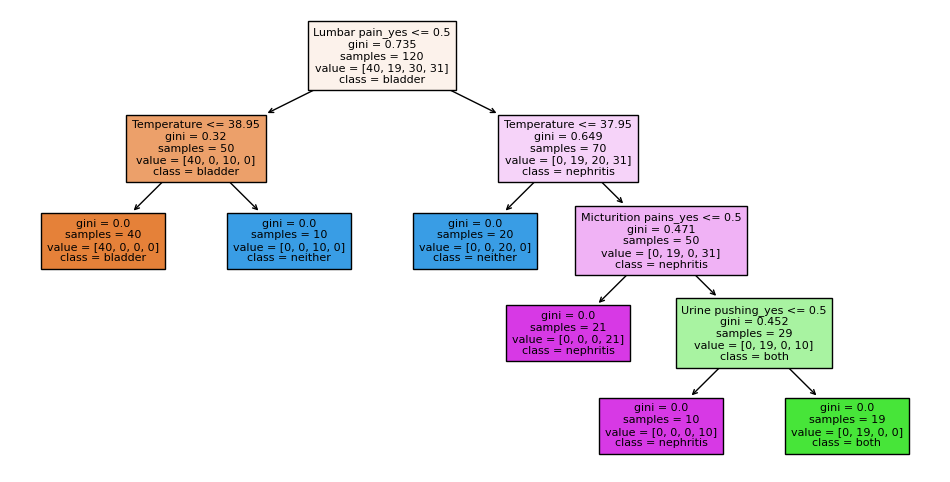

leaves: 6 | depth: 4 | train acc: 1.0


In [2]:
tree = DecisionTreeClassifier(random_state=0).fit(X, y)

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_), filled=True, fontsize=8)
plt.show()
print('leaves:', tree.get_n_leaves(), '| depth:', tree.get_depth(), '| train acc:', tree.score(X, y))

The tree has 6 leaves and depth 4, and it classifies all 120 patients correctly (every leaf is pure). The first split is lumbar pain, then body temperature, and the last two splits (micturition pains, urine pushing) are only needed to tell nephritis from "both".

## 1(c) IF-THEN rules

In [3]:
def tree_to_rules(tree, names):
    t = tree.tree_
    def walk(node, conds):
        if t.feature[node] == -2:                     # leaf
            cls = tree.classes_[t.value[node].argmax()]
            print('IF ' + ' AND '.join(conds) + f' THEN diagnosis = {cls} ({int(t.n_node_samples[node])} patients)')
            return
        name, thr = names[t.feature[node]], t.threshold[node]
        if name.endswith('_yes'):                     # yes/no features
            left, right = f'{name[:-4]} = no', f'{name[:-4]} = yes'
        else:
            left, right = f'{name} <= {thr:.2f}', f'{name} > {thr:.2f}'
        walk(t.children_left[node], conds + [left])
        walk(t.children_right[node], conds + [right])
    walk(0, [])

tree_to_rules(tree, list(X.columns))

IF Lumbar pain = no AND Temperature <= 38.95 THEN diagnosis = bladder (40 patients)
IF Lumbar pain = no AND Temperature > 38.95 THEN diagnosis = neither (10 patients)
IF Lumbar pain = yes AND Temperature <= 37.95 THEN diagnosis = neither (20 patients)
IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = no THEN diagnosis = nephritis (21 patients)
IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = no THEN diagnosis = nephritis (10 patients)
IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = yes THEN diagnosis = both (19 patients)


The six rules cover all 120 patients (40 + 10 + 20 + 21 + 10 + 19). Lumbar pain and temperature decide most cases; micturition pains and urine pushing are only needed to separate "nephritis" from "both".

## 1(d) Cost-complexity pruning

In [4]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
alphas = tree.cost_complexity_pruning_path(X, y).ccp_alphas

rows = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=0, ccp_alpha=a)
    acc = cross_val_score(m, X, y, cv=cv)
    rows.append({'ccp_alpha': a, 'leaves': m.fit(X, y).get_n_leaves(),
                 'cv_acc': acc.mean(), 'se': acc.std() / np.sqrt(5)})
pruning = pd.DataFrame(rows)
pruning.round(4)

,ccp_alpha,leaves,cv_acc,se
0,0.0000,6,0.9917,0.0075
1,0.0982,4,0.8583,0.0224
2,0.1333,3,0.7583,0.0183
3,0.1820,2,0.6833,0.0303
4,0.2229,1,0.4833,0.0548


In [5]:
# one-SE rule: smallest tree that's within one SE of the best cv accuracy
best = pruning['cv_acc'].idxmax()
ok = pruning[pruning['cv_acc'] >= pruning.loc[best, 'cv_acc'] - pruning.loc[best, 'se']]
alpha = ok.loc[ok['leaves'].idxmin(), 'ccp_alpha']

final = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha).fit(X, y)
print('alpha:', alpha, '| leaves:', final.get_n_leaves(), '| train acc:', final.score(X, y))

# next pruned tree (4 leaves), to see what we lose
small = DecisionTreeClassifier(random_state=0, ccp_alpha=alphas[1]).fit(X, y)
print('4-leaf tree, cv acc:', round(pruning.loc[1, 'cv_acc'], 3), '| train acc:', round(small.score(X, y), 3))
tree_to_rules(small, list(X.columns))

alpha: 0.0 | leaves: 6 | train acc: 1.0
4-leaf tree, cv acc: 0.858 | train acc: 0.842
IF Lumbar pain = no AND Temperature <= 38.95 THEN diagnosis = bladder (40 patients)
IF Lumbar pain = no AND Temperature > 38.95 THEN diagnosis = neither (10 patients)
IF Lumbar pain = yes AND Temperature <= 37.95 THEN diagnosis = neither (20 patients)
IF Lumbar pain = yes AND Temperature > 37.95 THEN diagnosis = nephritis (50 patients)


Pruning doesn't help here. The unpruned tree (alpha = 0, 6 leaves) has the best cv accuracy (0.992), and with the one-SE rule it is also the one selected. Pruning it to 4 leaves drops the cv accuracy to 0.858, because "nephritis" and "both" get merged and patients with both diseases can't be told apart anymore. So the six rules in 1(c) are the final rule set: small enough to read, and no accuracy is lost.

# 2. The LASSO and Boosting for Regression

## 2(a) Data and train/test split

Column names come from the `attribute` lines of `communities.names`, and `?` marks a missing value. The first 1495 rows are the training set, the remaining 499 rows the test set.

In [6]:
import re
import seaborn as sns
from sklearn.impute import SimpleImputer

with open(os.path.join(os.getcwd(), 'communities.names')) as f:
    names = [re.match(r'@attribute (\S+)', line).group(1) for line in f if line.startswith('@attribute')]

df = pd.read_csv(os.path.join(os.getcwd(), 'communities.data'), header=None, names=names, na_values='?')
train, test = df.iloc[:1495], df.iloc[1495:]
print(df.shape, train.shape, test.shape)

(1994, 128) (1495, 128) (499, 128)


## 2(b) Missing values

The first 5 columns (state, county, community, communityname, fold) are non-predictive, so I drop them before imputing. 22 of the police-related columns are missing in 84% of the rows, and `OtherPerCap` has a single missing value. I keep all 122 predictors and fill the missing values with the training-set mean (the test set gets the same training means, so nothing leaks from the test data).

In [7]:
drop = ['state', 'county', 'community', 'communityname', 'fold']      # not predictive
goal = 'ViolentCrimesPerPop'
X_train, y_train = train.drop(columns=drop + [goal]), train[goal]
X_test, y_test = test.drop(columns=drop + [goal]), test[goal].reset_index(drop=True)

miss = X_train.isna().mean()
print(int((miss > 0).sum()), 'columns with missing values (share of rows missing):')
print(miss[miss > 0].round(2).value_counts())

# fill with train means only
imp = SimpleImputer(strategy='mean').fit(X_train)
X_train = pd.DataFrame(imp.transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(imp.transform(X_test), columns=X_test.columns)
print(X_train.shape, X_test.shape, '| missing left:', X_train.isna().sum().sum() + X_test.isna().sum().sum())

23 columns with missing values (share of rows missing):
0.84    22
0.00     1
Name: count, dtype: int64
(1495, 122) (499, 122) | missing left: 0


## 2(c) Correlation matrix

With 122 features a plain correlation matrix is unreadable, so I use a clustered heatmap (features are reordered by hierarchical clustering, so correlated features end up next to each other). Labels are left out because there are too many to read.

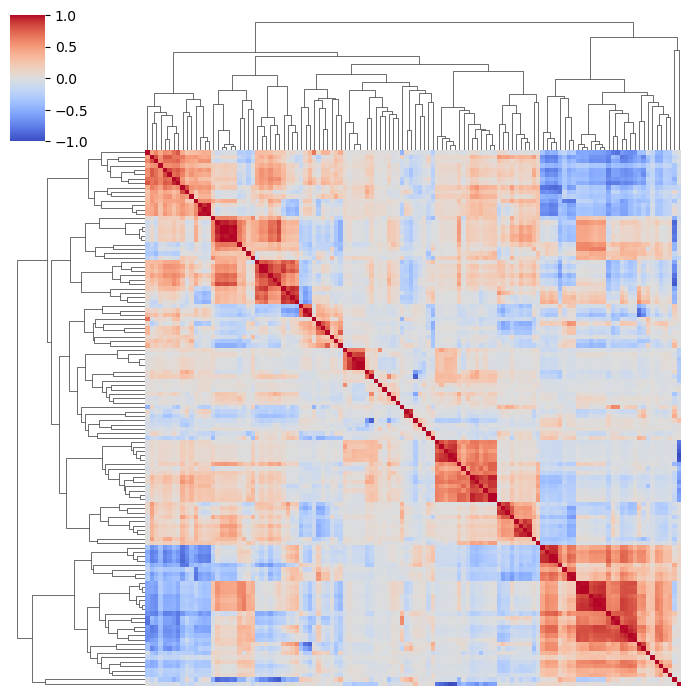

pairs with |r| > 0.9: 61 of 7381


In [8]:
import warnings
warnings.filterwarnings('ignore', message='Clustering large matrix')    # just a speed hint from seaborn

corr = X_train.corr()
sns.clustermap(corr, cmap='coolwarm', vmin=-1, vmax=1, figsize=(7, 7), xticklabels=False, yticklabels=False)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('pairs with |r| > 0.9:', int((pairs.abs() > 0.9).sum()), 'of', len(pairs))

## 2(d) Coefficient of variation

CV = s / m for every feature, computed on the (imputed) training set with the sample standard deviation. All feature means are positive, so there is no division by zero.

In [9]:
cv_coef = X_train.std() / X_train.mean()

print(cv_coef.describe().round(3).to_string())
print()
print(cv_coef.sort_values(ascending=False).head(11).round(3).to_string())

count    122.000
mean       0.740
std        0.687
min        0.064
25%        0.343
50%        0.518
75%        0.817
max        4.293

NumStreet              4.293
NumInShelters          3.471
NumIlleg               3.059
NumImmig               2.927
LemasPctOfficDrugUn    2.553
NumUnderPov            2.342
population             2.241
numbUrban              2.038
HousVacant             1.968
LandArea               1.645
racePctHisp            1.612


## 2(e) Scatter plots and box plots of the 11 features with the highest CV

floor(sqrt(128)) = 11. Scatter plots show each feature against `ViolentCrimesPerPop` (training set), and the box plots show the distribution of each feature.

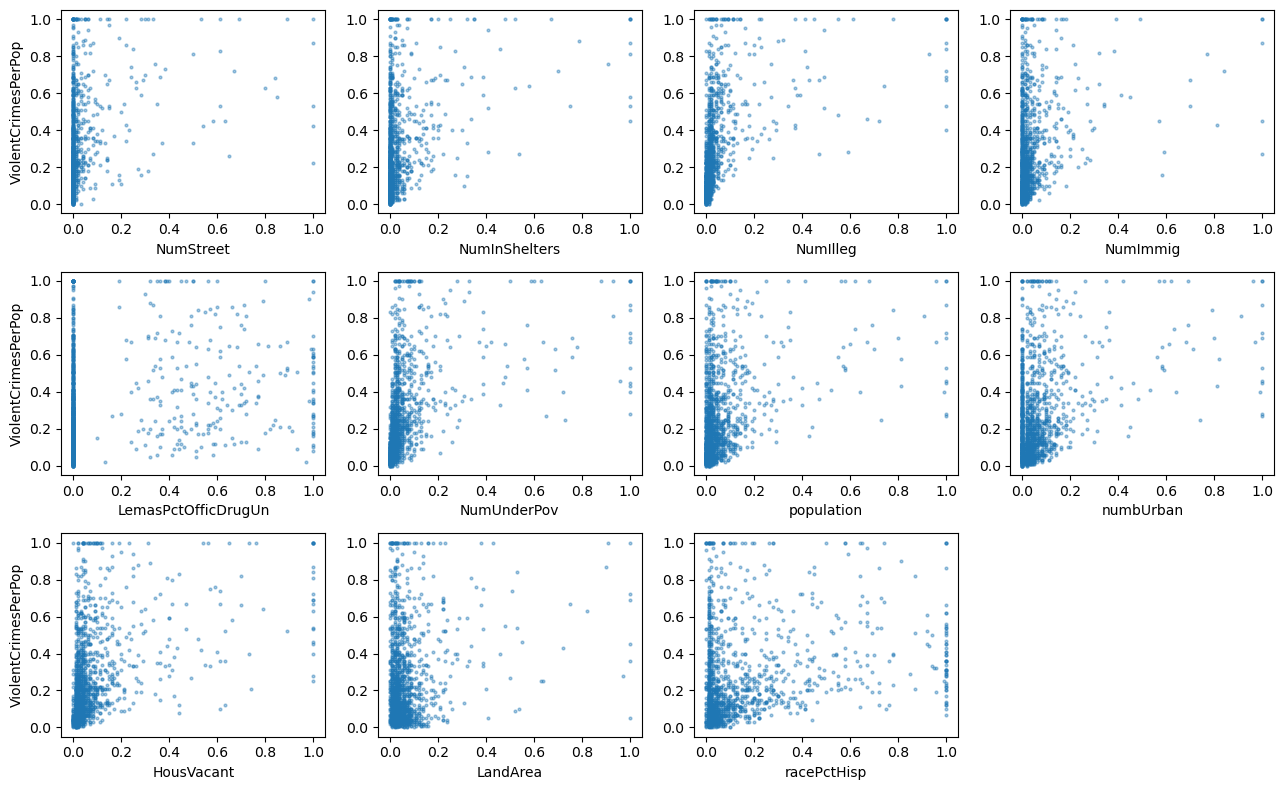

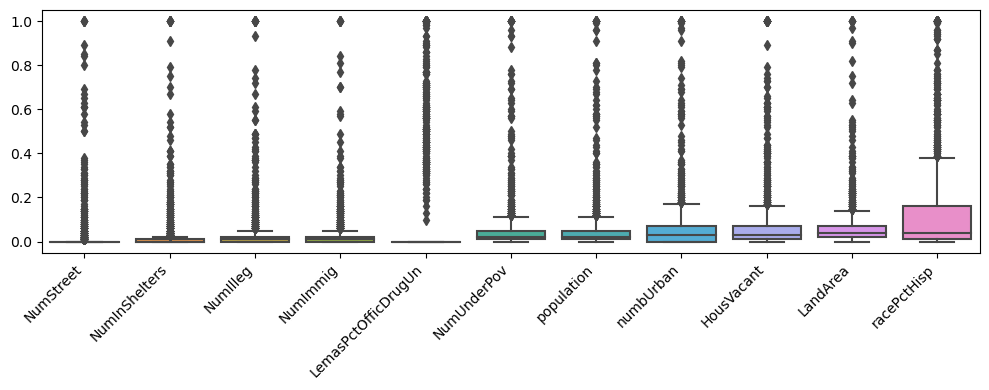

In [10]:
top = cv_coef.sort_values(ascending=False).head(11).index

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, c in zip(axes.flat, top):
    ax.scatter(X_train[c], y_train, s=4, alpha=0.4)
    ax.set_xlabel(c)
for ax in axes[:, 0]:
    ax.set_ylabel(goal)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=X_train[top])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Most communities have values close to 0 for these features, and a few large ones have very large values (the box plots show many outliers). Most features show a weak upward trend with the crime rate, but the points are very spread out.

We can't conclude significance from the scater plots alone. They only show the relationship with the response for one feature at a time, so they can't tell whether a feature still matters once the others are in the model (many of these features are strongly correlated, like population and numbUrban, r = 0.99). The points also pile up near 0, so a trend is hard to tell from noise or outliers.

## 2(f) Least squares

Linear regression on the training set; the test error is the mean squared error (MSE) on the test set.

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

results = {}                      # test MSE of every model, for the comparison at the end

ols = LinearRegression().fit(X_train, y_train)
results['OLS'] = mean_squared_error(y_test, ols.predict(X_test))

print('train MSE:', round(mean_squared_error(y_train, ols.predict(X_train)), 4))
print('test MSE:', round(results['OLS'], 4))

train MSE: 0.0163
test MSE: 0.0181


## 2(g) Ridge regression

Features are standardized first (the usual way for ridge, since the penalty depends on the scale of the features). The standardization is part of a pipeline, so in the cross-validation it is fitted only on the training part of each fold. lambda (`alpha` in sklearn) is chosen by 5-fold cross-validation over a log-spaced grid.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

kf = KFold(n_splits=5, shuffle=True, random_state=0)
alphas = np.logspace(-2, 3, 40)

ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': alphas},
                     cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
results['Ridge'] = mean_squared_error(y_test, ridge.predict(X_test))

print('best lambda:', round(ridge.best_params_['ridge__alpha'], 2))
print('cv MSE:', round(-ridge.best_score_, 4), '| test MSE:', round(results['Ridge'], 4))

best lambda: 94.27
cv MSE: 0.0192 | test MSE: 0.0175


## 2(h) LASSO

lambda is chosen by 5-fold cross-validation, first on the original features (they are already in [0, 1]), then on standardized features.



### Original features

In [13]:
import textwrap
from sklearn.linear_model import Lasso

lasso_raw = GridSearchCV(Lasso(max_iter=50000), {'alpha': np.logspace(-6, -1, 40)},
                         cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
coef_raw = pd.Series(lasso_raw.best_estimator_.coef_, index=X_train.columns)
coef_raw = coef_raw[coef_raw != 0]
results['LASSO'] = mean_squared_error(y_test, lasso_raw.predict(X_test))

print('best lambda:', round(lasso_raw.best_params_['alpha'], 6), '| test MSE:', round(results['LASSO'], 4))
print(len(coef_raw), 'variables selected:')
print(textwrap.fill(', '.join(coef_raw.abs().sort_values(ascending=False).index), 110))

best lambda: 8.4e-05 | test MSE: 0.0178
80 variables selected:
agePct12t29, racepctblack, PctPersDenseHous, PctKids2Par, MedRent, NumStreet, PctEmploy, RentLowQ,
MalePctNevMarr, PctPopUnderPov, MalePctDivorce, PctWorkMom, HousVacant, pctWInvInc, FemalePctDiv,
PctLargHouseOccup, pctWRetire, PersPerOccupHous, PolicReqPerOffic, pctWWage, PctIlleg, NumImmig,
MedRentPctHousInc, LemasSwFTFieldPerPop, PctNotSpeakEnglWell, whitePerCap, agePct12t21, MedOwnCostPctIncNoMtg,
PctVacantBoarded, PctHousLess3BR, PctPersOwnOccup, NumInShelters, NumIlleg, pctWSocSec, PctVacMore6Mos,
PctForeignBorn, PctHousOccup, LemasTotalReq, PctUsePubTrans, LandArea, pctWPubAsst, PctPolicBlack, pctUrban,
LemasGangUnitDeploy, PctRecImmig10, NumKindsDrugsSeiz, PctBSorMore, PctYoungKids2Par, indianPerCap,
pctWFarmSelf, AsianPerCap, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, HispPerCap, PctSameCity85,
OtherPerCap, PctLess9thGrade, blackPerCap, PctOccupManu, LemasPctPolicOnPatr, PctEmplManu, RacialMatchCommPol,
MedOwn

### Standardized features

In [14]:
lasso_std = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=50000)),
                         {'lasso__alpha': np.logspace(-4, 0, 40)},
                         cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
coef_std = pd.Series(lasso_std.best_estimator_.named_steps['lasso'].coef_, index=X_train.columns)
coef_std = coef_std[coef_std != 0]
results['LASSO (standardized)'] = mean_squared_error(y_test, lasso_std.predict(X_test))

print('best lambda:', round(lasso_std.best_params_['lasso__alpha'], 6), '| test MSE:', round(results['LASSO (standardized)'], 4))
print(len(coef_std), 'variables selected:')
print(textwrap.fill(', '.join(coef_std.abs().sort_values(ascending=False).index), 110))

both = set(coef_raw.index) & set(coef_std.index)
print('\nin both:', len(both), '| only raw:', sorted(set(coef_raw.index) - both),
      '| only standardized:', sorted(set(coef_std.index) - both))

best lambda: 0.000661 | test MSE: 0.0178
76 variables selected:
racepctblack, PctPersDenseHous, agePct12t29, PctKids2Par, RentLowQ, MedRent, PctPopUnderPov, PctEmploy,
PctIlleg, MalePctNevMarr, PctWorkMom, pctWInvInc, MalePctDivorce, NumStreet, HousVacant, pctWRetire, pctUrban,
MedRentPctHousInc, PctVacantBoarded, MedOwnCostPctIncNoMtg, pctWWage, FemalePctDiv, agePct12t21, PctHousOccup,
PctNotSpeakEnglWell, PctLargHouseOccup, PctVacMore6Mos, PctPersOwnOccup, PctHousLess3BR, whitePerCap,
pctWSocSec, PctUsePubTrans, PolicReqPerOffic, NumImmig, PctRecImmig10, PctYoungKids2Par, LemasSwFTFieldPerPop,
NumInShelters, LemasTotalReq, PersPerOccupHous, PctForeignBorn, pctWPubAsst, LemasGangUnitDeploy, LandArea,
NumIlleg, AsianPerCap, indianPerCap, PctPolicBlack, PctWOFullPlumb, PolicCars, pctWFarmSelf, HispPerCap,
OtherPerCap, blackPerCap, MedOwnCostPctInc, PopDens, PctSameCity85, PctHousNoPhone, MedYrHousBuilt,
OfficAssgnDrugUnits, NumKindsDrugsSeiz, PctLess9thGrade, PolicAveOTWorked, RacialMat

Both versions give the same test MSE (0.0178), a bit lower than least squares (0.0181) and slightly higher than ridge (0.0175). The original-feature LASSO keeps 80 variables and the standardized one 76; 75 of them are the same. The two versions are so similar because the features are already scaled to [0, 1], so standardizing changes little. The lambda values differ (8.4e-05 vs 0.000661) because lambda depends on the scale of the features. The model keeps most of the 122 variables, which is expected since many of them are correlated and each carries a little information.

## 2(i) Principal component regression

Standardize the features, take the first M principal components, and run least squares on them. M is chosen by 5-fold cross-validation (M = 1, ..., 122), with the standardization and PCA inside the pipeline so they are refitted in every fold.

best M: 97 | cv MSE: 0.0195 | test MSE: 0.0185


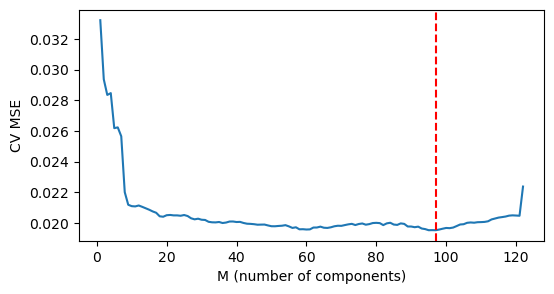

In [15]:
from sklearn.decomposition import PCA

pcr = GridSearchCV(make_pipeline(StandardScaler(), PCA(svd_solver='full'), LinearRegression()),
                   {'pca__n_components': range(1, 123)}, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
results['PCR'] = mean_squared_error(y_test, pcr.predict(X_test))
M = pcr.best_params_['pca__n_components']
print('best M:', M, '| cv MSE:', round(-pcr.best_score_, 4), '| test MSE:', round(results['PCR'], 4))

plt.figure(figsize=(6, 3))
plt.plot(range(1, 123), -pcr.cv_results_['mean_test_score'])
plt.axvline(M, color='r', ls='--')
plt.xlabel('M (number of components)')
plt.ylabel('CV MSE')
plt.show()


The cross-validation picks M = 97 components, with a test MSE of 0.0185, a bit worse than least squares (0.0181), ridge (0.0175) and the LASSO (0.0178). The CV curve drops quickly up to about 20 components and is almost flat from about 40 on, so the exact M is not important: most of the useful information is in the first components, and the later ones add little.

## 2(j) L1-penalized gradient boosting trees (XGBoost)

I use XGBoost's gradient boosted trees, where `reg_alpha` is the L1 penalty on the leaf weights (the alpha of the question). It is chosen by 5-fold cross-validation; the other settings are fixed (300 trees, learning rate 0.05, depth 3).

In [16]:
from xgboost import XGBRegressor

alphas_xgb = [0, 0.01, 0.1, 1, 3, 10, 30, 100]
xgb = GridSearchCV(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0),
                   {'reg_alpha': alphas_xgb}, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
results['XGBoost (L1)'] = mean_squared_error(y_test, xgb.predict(X_test))

print(pd.DataFrame({'reg_alpha': alphas_xgb, 'cv MSE': -xgb.cv_results_['mean_test_score']}).round(4).to_string(index=False))
print('best alpha:', xgb.best_params_['reg_alpha'], '| test MSE:', round(results['XGBoost (L1)'], 4))

imp = pd.Series(xgb.best_estimator_.feature_importances_, index=X_train.columns)
print(imp.sort_values(ascending=False).head(5).round(3).to_string())

 reg_alpha  cv MSE
      0.00  0.0199
      0.01  0.0199
      0.10  0.0196
      1.00  0.0195
      3.00  0.0198
     10.00  0.0214
     30.00  0.0282
    100.00  0.0566
best alpha: 1 | test MSE: 0.0163
PctIlleg        0.271
PctKids2Par     0.191
NumIlleg        0.045
racePctWhite    0.040
PctFam2Par      0.037


The cross-validation picks alpha = 1. Very small values hardly penalize anything, and from alpha = 10 on the penalty is too strong (at alpha = 100 most leaf weights are shrunk to zero and the CV MSE is 0.0566). The test MSE is 0.0163, the lowest of all models, but the CV MSE (0.0195) is about the same as for ridge and the LASSO, so the gap on the test set should not be over-interpreted. The boosted trees rely mostly on `PctIlleg` and `PctKids2Par`, which are also among the first variables selected by the LASSO.

In [17]:
pd.Series(results, name='test MSE').round(4).sort_values().to_frame()

,test MSE
XGBoost (L1),0.0163
Ridge,0.0175
LASSO,0.0178
LASSO (standardized),0.0178
OLS,0.0181
PCR,0.0185



The boosted trees have the lowest test MSE (0.0163). The linear models are all close (0.0175 to 0.0185), so the choice among them matters little. Boosting may be picking up non-linear effects or interactions that the linear models miss, but its cross-validation MSE (0.0195) is about the same as for ridge and the LASSO (about 0.019), so I would not read too much into the gap on the test set.